## Descarca datasetul

In [1]:
import kagglehub
from pathlib import Path
import tarfile

dataset_path = Path(kagglehub.dataset_download("jessicali9530/lfw-dataset"))
lfw_candidates = [
    candidate
    for candidate in dataset_path.rglob("lfw-deepfunneled")
    if candidate.is_dir()
    and any(
        person_dir.is_dir()
        and any(image.suffix.lower() in {".jpg", ".jpeg"} for image in person_dir.iterdir())
        for person_dir in candidate.iterdir()
    )
]
if not lfw_candidates:
    raise FileNotFoundError(f"Could not find the LFW image folders in {dataset_path}")

LFW_PATH = lfw_candidates[0]
archive_path = Path("lfw.tgz")
with tarfile.open(archive_path, "w:gz") as archive:
    archive.add(LFW_PATH, arcname="lfw")

print(f"LFW images: {LFW_PATH}")
print(f"Created archive: {archive_path.resolve()}")

d:\Proiecte\face_recognition\FaceRecognition\.venv310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


LFW images: C:\Users\Cata\.cache\kagglehub\datasets\jessicali9530\lfw-dataset\versions\4\lfw-deepfunneled\lfw-deepfunneled
Created archive: D:\Proiecte\face_recognition\FaceRecognition\lfw.tgz


## Importa biblioteci

In [2]:
import cv2
import os
import numpy as np
import random
import shutil
from matplotlib import pyplot as plt
import uuid #for unique image names
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Layer,Conv2D,Dense,MaxPooling2D,Input,Flatten
import tensorflow as tf

## Verifica placa

In [3]:

#Avoid oom
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
    details = tf.config.experimental.get_device_details(gpu)
    print(details.get(gpu.name))

print(gpus)

import subprocess
print(subprocess.check_output([
    "nvidia-smi",
    "--query-gpu=name,memory.total",
    "--format=csv,noheader"
], text=True))

None
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144 MiB



## Pregateste folderele

In [56]:


POST_PATH = os.path.join('data','positive')
NEG_PATH = os.path.join('data','negative')
ANC_PATH = os.path.join('data','anchor')
WNEG_PATH = os.path.join('data','webcam_negative')

os.makedirs(POST_PATH,exist_ok=True)
os.makedirs(NEG_PATH,exist_ok=True)
os.makedirs(ANC_PATH,exist_ok=True)
os.makedirs(WNEG_PATH,exist_ok=True)


for directory in os.listdir(LFW_PATH):
    for file in os.listdir(os.path.join(LFW_PATH, directory)):
        EX_PATH = os.path.join(LFW_PATH, directory, file)
        NEW_PATH = os.path.join(NEG_PATH,file)
        shutil.copy2(EX_PATH,NEW_PATH)



## Colecteaza imagini

In [ ]:
cap = cv2.VideoCapture(0)
while cap.isOpened():
    ret, frame = cap.read()
    #cut frame to 250x250
    frame = frame[170:420, 190:440, :]
    key = cv2.waitKey(1) & 0xFF
    #anchor
    if key == ord('a'):
        imgname = os.path.join(ANC_PATH,'{}.jpg'.format(uuid.uuid1()))
        cv2.imwrite(imgname,frame)

    #pozitive
    if key == ord('p'):
        imgname = os.path.join(POST_PATH, '{}.jpg'.format(uuid.uuid1()))
        cv2.imwrite(imgname, frame)
    #negative
    if key == ord('n'):
        imgname = os.path.join(WNEG_PATH, '{}.jpg'.format(uuid.uuid1()))
        cv2.imwrite(imgname, frame)

    #quit
    cv2.imshow('Image Collection',frame)
    if key == ord('q'):
        break
cap.release()
cv2.destroyAllWindows()



## incarca fisierele

In [57]:
anchor = tf.data.Dataset.list_files(os.path.join(ANC_PATH, "*.jpg")).take(300)
positive = tf.data.Dataset.list_files(os.path.join(POST_PATH, "*.jpg")).take(300)
negative = tf.data.Dataset.list_files(os.path.join(NEG_PATH, "*.jpg")).take(40)
webcam_negative = tf.data.Dataset.list_files(os.path.join(WNEG_PATH, "*.jpg")).take(40)

def preprocess(file_path):
    byte_img = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(byte_img)
    img = tf.image.resize(img, (100, 100))
    img = img / 255.0
    return img

img = preprocess(next(iter(anchor)))
#plt.imshow(img)
#plt.show()

#(anchor, positive) => 1,1,1,1,1
#(anchor,negative) => 0,0,0,0,0



## Pregateste perechile

In [58]:
positives = tf.data.Dataset.zip((anchor,positive,tf.data.Dataset.from_tensor_slices(tf.ones(len(anchor)))))
negatives = tf.data.Dataset.zip((anchor,negative,tf.data.Dataset.from_tensor_slices(tf.zeros(len(anchor)))))
webcam_negatives = tf.data.Dataset.zip((anchor,webcam_negative,tf.data.Dataset.from_tensor_slices(tf.zeros(len(anchor)))))
data = positives.concatenate(negatives).concatenate(webcam_negatives)

def preprocess_twin(input_img,validation_img,label):
    return preprocess(input_img),preprocess(validation_img),label

#dataloader pipeline
data = data.map(preprocess_twin)
data = data.cache()
data = data.shuffle(buffer_size=1024)

# samples = data.as_numpy_iterator()
# samp = samples.next()
# #create 2 subplots to see anchor and positive/negative
# fig, ax = plt.subplots(1, 2, figsize=(6,3))
# ax[0].imshow(samp[0])
# ax[0].set_title("Anchor")
# ax[0].axis('off')
# ax[1].imshow(samp[1])
# ax[1].set_title("Positive/Negative")
# ax[1].axis('off')
# plt.show()

# #print label 0 - negative sample, 1 - positive sample
# print(samp[2])




## Separa datele

In [59]:
#training partition
size = tf.data.experimental.cardinality(data).numpy()
train_data = data.take(round(size*0.7))
train_data = train_data.batch(16)
train_data = train_data.prefetch(8)
#train_samples = train_data.as_numpy_iterator()
#train_samp = train_samples.next()
#print(len(train_samp[0]))

#testing partition
test_data = data.skip(round(size*0.7))
test_data = test_data.take(round(size*0.3))
test_data = test_data.batch(16)
test_data = test_data.prefetch(8)




## Construieste modelul

In [60]:
#Build Embedding Model
#Convolution -> MaxPooling -> Conv -> MaxPooling -> Conv -> MaxPooling -> Conv -> Flatten -> Dense
#Pipeline for feature extraction
def make_embedding():
    inp = Input(shape = (100,100,3), name  = 'inp_image')
    #intern while
    #learns simple details-> edges, lines, corners
    conv1 = Conv2D(64,(10,10),activation='relu')(inp)
    mp1 = MaxPooling2D((2,2), padding = 'same')(conv1)
    
    #learns facial features -> curbs of the face, textures, shapes
    conv2 = Conv2D(128,(7,7),activation='relu')(mp1)
    mp2 = MaxPooling2D((2,2), padding = 'same')(conv2)
    
    #complex features -> the shape of nose, eyes, lips
    conv3 = Conv2D(128,(4,4),activation='relu')(mp2)
    mp3 = MaxPooling2D((2,2), padding = 'same')(conv3)
    
    #fine details -> distance between eyes, nose tip to chin
    conv4 = Conv2D(256,(4,4),activation='relu')(mp3)
    
    flat = Flatten()(conv4)
    dense = Dense(4096,activation='sigmoid')(flat)
    # Numeric code of the image
    #the model has an input image and outputs a vector of 4096 numbers
    return Model(inputs=inp,outputs=dense, name='embedding_model')

#print(make_embedding().summary())


#Distance Layer for the siamese network
class L1Dist(Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    #similarity calculation
    def call(self, input_embedding, validation_embedding): #input_embedding - anchor, validation_embedding - positive/negative
        return tf.math.abs(input_embedding - validation_embedding)
    

embedding = make_embedding()
def make_siamese_model():
    input = Input(name='input_img', shape=(100,100,3))
    validation = Input(name='validation_img', shape=(100,100,3))
    
    siamese_layer = L1Dist()
    siamese_layer._name = 'distance'
    distances = siamese_layer(embedding(input), embedding(validation))
    
    classifier = Dense(1, activation='sigmoid')(distances)

    return Model(inputs=[input, validation], outputs=classifier, name='SiameseNetwork')

siamese_model = make_siamese_model()
#print(siamese_model.summary())



## Defineste antrenarea

In [61]:
binary_cross_loss = tf.losses.BinaryCrossentropy()
opt = tf.keras.optimizers.Adam(1e-4)

checkpoint_dir = './training_checkpoints'
checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
checkpoint = tf.train.Checkpoint(opt=opt, siamese_model=siamese_model)

@tf.function
def train_step(batch):
    #record all operations
    with tf.GradientTape() as tape:
        #get anchor and positive/negative image
        X = batch[:2]
        #get label
        y = batch[2]
        #forward pass
        yhat = siamese_model(X, training=True)
        #calculate loss
        loss = binary_cross_loss(y, yhat)
    pass 
    print(loss)

    grad = tape.gradient(loss, siamese_model.trainable_variables)
    opt.apply_gradients(zip(grad, siamese_model.trainable_variables))
    return loss

def train(data, EPOCHS):
    #loop over epochs
    #Epochs is the number of times the model sees the data
    for epoch in range(1,EPOCHS+1):
        print("\n Epoch {}/{}".format(epoch,EPOCHS))
        progbar = tf.keras.utils.Progbar(len(data))

        #loop over each batch
        for idx, batch in enumerate(data):
            loss = train_step(batch)
            progbar.update(idx+1, [("loss", loss)])

        #checkpoints
        if epoch % 10 == 0:
            checkpoint.save(file_prefix=checkpoint_prefix)




## Antreneaza modelul

In [62]:
EPOCHS = 27
train(train_data, EPOCHS)






 Epoch 1/27
Tensor("binary_crossentropy/weighted_loss/value:0", shape=(), dtype=float32)
Tensor("binary_crossentropy/weighted_loss/value:0", shape=(), dtype=float32)
17/17 [==============================] - 7s 336ms/step - loss: 0.6076

 Epoch 2/27
17/17 [==============================] - 2s 111ms/step - loss: 0.3794

 Epoch 3/27
17/17 [==============================] - 2s 110ms/step - loss: 0.3050

 Epoch 4/27
17/17 [==============================] - 2s 103ms/step - loss: 0.2041

 Epoch 5/27
17/17 [==============================] - 2s 102ms/step - loss: 0.1255

 Epoch 6/27
17/17 [==============================] - 2s 101ms/step - loss: 0.1372

 Epoch 7/27
17/17 [==============================] - 2s 100ms/step - loss: 0.0884

 Epoch 8/27
17/17 [==============================] - 2s 99ms/step - loss: 0.0420

 Epoch 9/27
17/17 [==============================] - 2s 100ms/step - loss: 0.0550

 Epoch 10/27
17/17 [==============================] - 2s 99ms/step - loss: 0.0518

 Epoch 11/27
17/

## Pregateste evaluarea

In [63]:
#Evaluating the model
from tensorflow.keras.metrics import Precision, Recall


## Alege batchul

In [64]:
test_input, test_val, y_true = test_data.as_numpy_iterator().next()


## Alege alt batch

In [65]:
test_var = test_data.as_numpy_iterator().next()

## Verifica dimensiunea

In [66]:
len(test_var)

3

## Noteaza testarea

In [67]:
#test_var[0] - test_input
#test_var[1] - test_val
#test_var[2] - y_true

## Prezice rezultatele

In [68]:
#make predictions
y_hat = predictions = siamese_model.predict([test_input, test_val])
y_hat

1/1 [==============================] - 0s 260ms/step


array([[9.9956769e-01],
       [9.9969709e-01],
       [9.9966073e-01],
       [9.9998868e-01],
       [1.2787781e-03],
       [9.9999952e-01],
       [9.9950016e-01],
       [9.9995339e-01],
       [9.9998474e-01],
       [3.3687661e-06],
       [9.9988103e-01],
       [9.9990690e-01],
       [5.4828848e-05],
       [1.0299406e-07],
       [9.9997520e-01],
       [9.9999356e-01]], dtype=float32)

## Transforma predictiile

In [69]:
# postprocessing results
[1 if prediction > 0.5 else 0 for prediction in y_hat]

[1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1]

## Vezi etichetele

In [70]:
y_true

array([1., 1., 1., 1., 0., 1., 1., 1., 1., 0., 1., 1., 0., 0., 1., 1.],
      dtype=float32)

## Calculeaza recall

In [71]:
m = Recall() # creating a metric object for rec
m.update_state(y_true, y_hat) #calc recall
m.result().numpy() # recall result

1.0

## Calculeaza precision

In [72]:
m = Precision() # creating a metric object for p
m.update_state(y_true, y_hat) #calc prec
m.result().numpy() # p result

1.0

## Compara imaginile

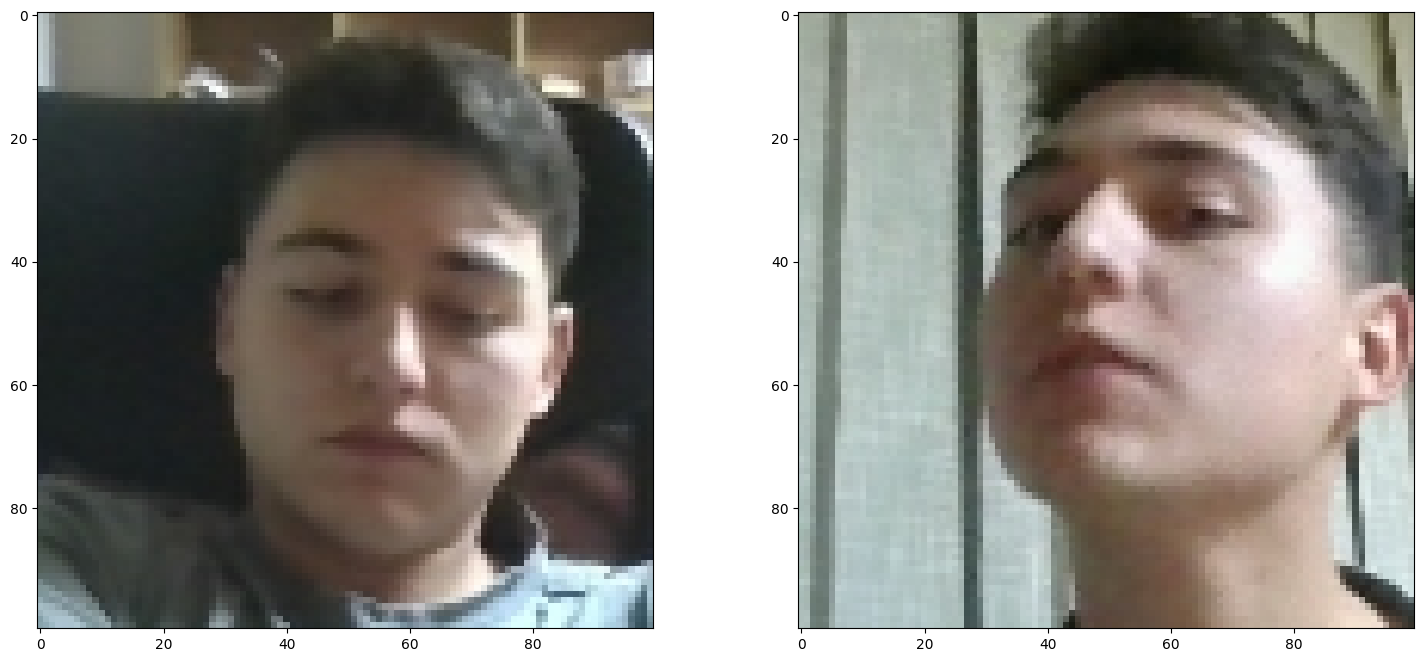

In [73]:
#visualise results
#using matplotlib
plt.figure(figsize = (18,8))
plt.subplot(1,2,1)
plt.imshow(test_input[3])
plt.subplot(1,2,2)
plt.imshow(test_val[3])
plt.show()

## Salveaza modelul

In [41]:
#saving the model
siamese_model.save('siamesemodel.h5')

## incarca modelul

In [42]:
model = tf.keras.models.load_model('siamesemodel.h5', custom_objects = {'L1Dist':L1Dist, 'BinaryCrossentropy':tf.losses.BinaryCrossentropy})

## Testeaza modelul

In [74]:
model.predict([test_input,test_val])

1/1 [==============================] - 0s 23ms/step


array([[1.0000000e+00],
       [9.9526322e-01],
       [9.9942821e-01],
       [1.0000000e+00],
       [3.6085769e-08],
       [9.9999988e-01],
       [9.9384850e-01],
       [9.9115819e-01],
       [6.4742512e-01],
       [3.3994154e-09],
       [9.9993777e-01],
       [8.2178259e-01],
       [5.4547047e-07],
       [4.6325654e-09],
       [9.9999714e-01],
       [9.9960977e-01]], dtype=float32)

## Vezi arhitectura

In [44]:
model.summary()

Model: "SiameseNetwork"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_img (InputLayer)         [(None, 100, 100, 3  0           []                               
                                )]                                                                
                                                                                                  
 validation_img (InputLayer)    [(None, 100, 100, 3  0           []                               
                                )]                                                                
                                                                                                  
 embedding_model (Functional)   (None, 4096)         38960448    ['input_img[0][0]',              
                                                                  'validation_img[0][

## Verifica identitatea

In [45]:
#verification function
def verify(model, detection_threshold, verification_threshold):
    results = []
    for image in os.listdir(os.path.join('application_data', 'verification_images')):
        input_img = preprocess(os.path.join('application_data','input_image', 'input_image.jpg'))
        validation_img = preprocess(os.path.join('application_data', 'verification_images', image))

        result = model.predict(list(np.expand_dims([input_img, validation_img], axis = 1)))
        results.append(result)


    detection = np.sum(np.array(results) > detection_threshold)
    verification = detection/ len(os.listdir(os.path.join('application_data', 'verification_images')))
    verified = verification > verification_threshold
    return results, verified


## Testeaza camera


In [75]:
cap = cv2.VideoCapture(0)
while cap.isOpened():
    ret, frame = cap.read()
    frame = frame[170:420, 190:440, :]
    cv2.imshow('Verification', frame)

    #verification trigger
    if cv2.waitKey(1) & 0xFF == ord('v'):
        #image to input image folder 
        cv2.imwrite(os.path.join('application_data', 'input_image', 'input_image.jpg'), frame)
        results, verified = verify(model, 0.6, 0.5)
        print(verified)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break
    
cap.release()
cv2.destroyAllWindows()


1/1 [==============================] - 0s 71ms/step
True
1/1 [==============================] - 0s 31ms/step
True
